Olá, Karyne

Meu nome é Ramon. Ao ao longo do texto farei algumas observações sobre melhorias no código. Nas partes em que não houver comentários, está tudo certo, ok? Estarei aberto a feedbacks e discussões sobre o tema.

**Peço que mantenha e não altere os comentários que eu fizer por aqui para que possamos nos localizar posteriormente, ok?**

Mais uma coisa, vamos utilizar um código de cores para você entender os meus feedbacks no seu notebook. Funciona assim:

<div class="alert alert-block alert-success">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
<b>Comentário do revisor: </b> <a class="tocSkip"></a>

Alerta não crítco, mas que pode ser corrigido para melhoria geral no seu código/análise
</div>

<div class="alert alert-block alert-danger">

<b>Comentário do revisor: </b> <a class="tocSkip"></a>
    
Erro que precisa ser consertado, caso contrário seu projeto **não** será aceito.
</div>

Você pode me responder usando isso:
<div class="alert alert-block alert-info">
<b>Resposta do Aluno.</b> <a class="tocSkip"></a>
</div>

###

<div class="alert alert-block alert-success">
<b>Comentário Geral do Revisor</b> <a class="tocSkip"></a>

Obrigado por enviar seu projeto. 
    
Parabéns, você fez um bom trabalho.

Como pontos fortes do projeto, destaco:
- Código simples e eficiente (sem loop desnecessário)
- Uso adequado dos recursos da lição

    
<span class="text-danger">Porém, há espaço para melhorias: </span>
 * <span class="text-danger"> ajustar fillna(), ajustar gráficos, apresentar gráficos, ajustar teste de hipótese </span>


Portanto, sugiro que você corrija os pontos indicados.
    
Se você tiver alguma dúvida sobre de algo que você não tenha entendido, sinta-se à vontade para perguntar ao tutor ou deixar um comentário em **azul** para que, na próxima iteração, eu possa responder.

Conte conosco. Lembre-se de que você pode tirar dúvidas com revisores usando os comentários ou buscar ajuda de um tutor.
Bom trabalho. 


</div>




<div class="alert alert-block alert-success">
<b> Comentário Geral do Revisor Final: </b> <a class="tocSkip"></a>

Houve melhoras no projeto. Parabéns pela dedicação. Deixei algumas observações na seção dos testes de hipótese. Desejo sucesso na jornada. Parabéns pelo empenho.
</div>


# Qual é o melhor plano?

Você trabalha como analista para a empresa de telecomunicações Megaline. A empresa oferece aos clientes dois planos pré-pagos: Surf e Ultimate. O departamento comercial quer saber qual dos planos gera mais receita para ajustar o orçamento de publicidade.

Você vai realizar uma análise preliminar dos planos com base em uma pequena seleção de clientes. Você terá dados de 500 clientes da Megaline: que clientes são, de onde eles são, qual plano usam e o número de chamadas e mensagens realizadas em 2018. Seu trabalho é analisar o comportamento dos clientes e determinar qual plano pré-pago gera mais receita.

[Fornecemos alguns comentários para guiar sua linha de raciocínio enquanto você trabalha neste projeto. Entretanto, certifique-se de remover todos os comentários entre colchetes antes de enviar o projeto.]

[Antes de começar a análise dos dados, explique com suas próprias palavras o propósito do projeto e as ações que planeja realizar.]

[Tenha em mente que estudar, modificar e analisar dados é um processo iterativo. É normal retornar a etapas anteriores e corrigir/expandir algo para permitir as próximas etapas.]

## Inicialização

In [1]:
# Carregando todas as bibliotecas
import pandas as pd
from scipy import stats as st
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn

## Carregue os dados

In [2]:
# Carregue os arquivos de dados em diferentes DataFrames
calls = pd.read_csv('/datasets/megaline_calls.csv')
internet = pd.read_csv('/datasets/megaline_internet.csv')
messages = pd.read_csv('/datasets/megaline_messages.csv')
plans = pd.read_csv('/datasets/megaline_plans.csv')
users =pd.read_csv('/datasets/megaline_users.csv')

## Prepare os dados

[Os dados deste projeto estão divididos em várias tabelas. Explore cada uma para obter uma compreensão inicial dos dados. Faça correções em cada tabela, se necessário.]

## Planos

In [3]:
# Imprima informações gerais/resumo sobre o DataFrame dos planos
plans.info()
plans.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
count,2.000000,2.000000,2.000000,2.000000,2.00000,2.000000,2.000000
mean,525.000000,23040.000000,1750.000000,45.000000,8.50000,0.020000,0.020000
std,671.751442,10861.160159,1767.766953,35.355339,2.12132,0.014142,0.014142
min,50.000000,15360.000000,500.000000,20.000000,7.00000,0.010000,0.010000
25%,287.500000,19200.000000,1125.000000,32.500000,7.75000,0.015000,0.015000
50%,525.000000,23040.000000,1750.000000,45.000000,8.50000,0.020000,0.020000
75%,762.500000,26880.000000,2375.000000,57.500000,9.25000,0.025000,0.025000
max,1000.000000,30720.000000,3000.000000,70.000000,10.00000,0.030000,0.030000


In [4]:
# Imprima uma amostra de dados dos planos
amostra = plans.sample(n=2)
amostra

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

## Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [5]:
plans['gb_per_month_included'] = plans['mb_per_month_included']/1024
print(f'Esse é o valor em GibaBytes:\n{plans["gb_per_month_included"]}')
display(plans)

Esse é o valor em GibaBytes:
0    15.0
1    30.0
Name: gb_per_month_included, dtype: float64


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included
0,50,15360,500,20,10,0.03,0.03,surf,15.0
1,1000,30720,3000,70,7,0.01,0.01,ultimate,30.0


## Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

## Usuários

In [6]:
# Imprima informações gerais/resumo sobre o DataFrame dos usuários
users.info()
users.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


,user_id,age
count,500.000000,500.000000
mean,1249.500000,45.486000
std,144.481833,16.972269
min,1000.000000,18.000000
25%,1124.750000,30.000000
50%,1249.500000,46.000000
75%,1374.250000,61.000000
max,1499.000000,75.000000


In [7]:
# Imprima uma amostra de dados dos usuários
amostra = users.sample(n=50)
amostra

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
156,1156,Anette,Chambers,71,"Albuquerque, NM MSA",2018-03-25,surf,NaN
355,1355,Digna,Tyson,57,"Los Angeles-Long Beach-Anaheim, CA MSA",2018-10-07,surf,NaN
373,1373,Lindsey,Dickerson,21,"Minneapolis-St. Paul-Bloomington, MN-WI MSA",2018-08-30,ultimate,NaN
228,1228,Jude,Hale,26,"Detroit-Warren-Dearborn, MI MSA",2018-04-15,surf,NaN
69,1069,Dino,Fry,31,"Houston-The Woodlands-Sugar Land, TX MSA",2018-09-17,ultimate,NaN
15,1015,Beata,Carpenter,26,"Pittsburgh, PA MSA",2018-12-05,surf,NaN
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaN
174,1174,Larisa,Ellis,67,"Cleveland-Elyria, OH MSA",2018-01-28,surf,NaN
340,1340,Vanna,Stanton,65,"Dallas-Fort Worth-Arlington, TX MSA",2018-07-05,surf,NaN
394,1394,Alejandro,Carver,28,"Stockton, CA MSA",2018-01-16,surf,NaN


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [8]:
users['reg_date_2'] = pd.to_datetime(users['reg_date'])
print(users['reg_date_2'].dt.strftime('%d-%m-%Y'))
display(users.dtypes)

0      24-12-2018
1      13-08-2018
2      21-10-2018
3      28-01-2018
4      23-05-2018
          ...    
495    04-09-2018
496    20-02-2018
497    10-12-2018
498    04-02-2018
499    06-05-2018
Name: reg_date_2, Length: 500, dtype: object


user_id                int64
first_name            object
last_name             object
age                    int64
city                  object
reg_date              object
plan                  object
churn_date            object
reg_date_2    datetime64[ns]
dtype: object

### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

## Chamadas

In [9]:
# Imprima informações gerais/resumo sobre o DataFrame das chamadas
calls.info()
calls.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB


,user_id,duration
count,137735.000000,137735.000000
mean,1247.658046,6.745927
std,139.416268,5.839241
min,1000.000000,0.000000
25%,1128.000000,1.290000
50%,1247.000000,5.980000
75%,1365.000000,10.690000
max,1499.000000,37.600000


In [10]:
# Imprima uma amostra de dados das chamadas
amostra = calls.sample(n=50)
amostra

,id,user_id,call_date,duration
61290,1220_696,1220,2018-05-29,1.97
41668,1153_434,1153,2018-11-08,6.61
122862,1434_162,1434,2018-07-06,1.49
114308,1400_658,1400,2018-03-21,10.38
112824,1397_491,1397,2018-12-01,11.98
64596,1234_1,1234,2018-12-26,17.56
22118,1082_51,1082,2018-09-11,0.00
29241,1110_292,1110,2018-08-14,1.67
84696,1312_188,1312,2018-10-12,2.77
79257,1284_207,1284,2018-10-02,9.42


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [11]:
calls['call_date'] = pd.to_datetime(calls['call_date'])
print(calls.info())
print()
calls['duration'] = calls['duration'].round().astype(int)
print(calls['duration'].unique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   id         137735 non-null  object        
 1   user_id    137735 non-null  int64         
 2   call_date  137735 non-null  datetime64[ns]
 3   duration   137735 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 4.2+ MB
None

[ 9 14  6  4  2 13  3 10  1 16  0  7 30 15 11 19  8 21 17  5 12 27 20 18
 26 25 22 23 24 29 32 31 28 36 38 34 33 35]


### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

## Mensagens

In [12]:
# Imprima informações gerais/resumo sobre o DataFrame das mensagens
messages.info()
messages.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB


,user_id
count,76051.000000
mean,1245.972768
std,139.843635
min,1000.000000
25%,1123.000000
50%,1251.000000
75%,1362.000000
max,1497.000000


In [13]:
# Imprima uma amostra dos dados das mensagens
amostra = messages.sample(n=50)
amostra

,id,user_id,message_date
28906,1176_47,1176,2018-12-13
11980,1079_379,1079,2018-11-25
63107,1401_19,1401,2018-11-28
21919,1132_1452,1132,2018-12-30
71990,1467_322,1467,2018-07-07
6919,1057_243,1057,2018-10-05
19975,1127_28,1127,2018-09-15
34482,1219_24,1219,2018-12-04
17078,1113_164,1113,2018-08-03
43129,1283_68,1283,2018-12-31


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [14]:
messages['message_date'] = pd.to_datetime(messages['message_date'])
messages['message_date_formatted'] = messages['message_date'].dt.strftime('%d-%m-%Y')
messages['message_date_formatted'] = pd.to_datetime(messages['message_date_formatted'])
display(messages.dtypes)

id                                object
user_id                            int64
message_date              datetime64[ns]
message_date_formatted    datetime64[ns]
dtype: object

### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

## Internet

In [15]:
# Imprima informações gerais/resumo sobre o DataFrame da internet
internet.info()
internet.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB


,user_id,mb_used
count,104825.000000,104825.000000
mean,1242.496361,366.713701
std,142.053913,277.170542
min,1000.000000,0.000000
25%,1122.000000,136.080000
50%,1236.000000,343.980000
75%,1367.000000,554.610000
max,1499.000000,1693.470000


In [16]:
#  Imprima uma amostra de dados para o tráfego da internet
amostra = internet.sample(n=50)
amostra

,id,user_id,session_date,mb_used
86712,1403_60,1403,2018-05-31,640.49
59296,1267_98,1267,2018-12-27,291.78
45584,1202_103,1202,2018-10-26,0.00
56220,1254_166,1254,2018-10-04,643.15
52326,1236_173,1236,2018-04-17,156.12
61472,1279_86,1279,2018-11-11,0.00
92862,1434_90,1434,2018-09-09,158.56
444,1004_25,1004,2018-10-09,69.37
18481,1082_197,1082,2018-11-02,831.42
26369,1122_324,1122,2018-12-11,0.00


[Descreva o que você nota sobre as informações gerais e sobre a amostra de dados impressa acima. Existem problemas (tipos de dados inadequados, dados ausentes, etc.) que precisam de mais investigação e alterações? Como isso pode ser corrigido?]

### Corrija os dados

[Corrija problemas óbvios com os dados conforme as observações iniciais.]

In [17]:
internet['session_date'] = pd.to_datetime(internet['session_date'])
internet['session_date_formatted'] = internet['session_date'].dt.strftime('%d-%m-%Y')

internet['gb_used'] = internet['mb_used']/1024
internet['gb_used'] = internet['gb_used'].round()
print(internet['gb_used'].sample(10))
display(internet)

78230    0.0
42789    0.0
64749    0.0
67209    1.0
91923    0.0
67290    1.0
53435    0.0
1712     1.0
28144    1.0
20196    1.0
Name: gb_used, dtype: float64


,id,user_id,session_date,mb_used,session_date_formatted,gb_used
0,1000_13,1000,2018-12-29,89.86,29-12-2018,0.0
1,1000_204,1000,2018-12-31,0.00,31-12-2018,0.0
2,1000_379,1000,2018-12-28,660.40,28-12-2018,1.0
3,1000_413,1000,2018-12-26,270.99,26-12-2018,0.0
4,1000_442,1000,2018-12-27,880.22,27-12-2018,1.0
...,...,...,...,...,...,...
104820,1499_215,1499,2018-10-20,218.06,20-10-2018,0.0
104821,1499_216,1499,2018-12-30,304.72,30-12-2018,0.0
104822,1499_217,1499,2018-09-22,292.75,22-09-2018,0.0
104823,1499_218,1499,2018-12-07,0.00,07-12-2018,0.0


### Enriqueça os dados

[Inclua fatores adicionais aos dados se você acredita que eles podem ser úteis.]

## Estude as condições dos planos

[É fundamental entender como os planos funcionam, ou seja, como as cobranças dos usuários são feitas com base na assinatura. Sugerimos imprimir as informações sobre os planos para visualizar novamente as condições.]

In [18]:
# Imprima as condições dos planos e certifique-se de que elas fazem sentido para você
plan_surf = plans[plans['plan_name'] == 'surf']
display(plan_surf)
print()
ultimate_surf = plans[plans['plan_name'] == 'ultimate']
display(ultimate_surf)

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included
0,50,15360,500,20,10,0.03,0.03,surf,15.0


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included
1,1000,30720,3000,70,7,0.01,0.01,ultimate,30.0


## Agregue os dados por usuário

[Agora, como os dados estão limpos, os agregue por usuário e por período para ter apenas um registro dessas informações. Isso vai facilitar muito as próximas análises.]

In [19]:
# Calcule o número de chamadas feitas por cada usuário por mês. Salve o resultado.
calls_per_user = calls.groupby('user_id').size().reset_index(name='total_calls')
display(calls_per_user.head())

,user_id,total_calls
0,1000,16
1,1001,261
2,1002,113
3,1003,149
4,1004,370


In [20]:
# Calcule a quantidade de minutos gastos por cada usuário por mês. Salve o resultado.
calls['month'] = calls['call_date'].dt.month
time_minute_per_user = calls.groupby(['user_id', 'month']).sum().reset_index()
display(time_minute_per_user.head())

,user_id,month,duration
0,1000,12,117
1,1001,8,173
2,1001,9,297
3,1001,10,374
4,1001,11,404


In [21]:
# Calcule o número de mensagens enviadas por cada usuário por mês. Salve o resultado.
messages['month'] = messages['message_date_formatted'].dt.month
number_messages_per_user = messages.groupby(['user_id', 'month']).size().reset_index(name='total_messages')
display(number_messages_per_user.head())

,user_id,month,total_messages
0,1000,12,11
1,1001,1,6
2,1001,2,6
3,1001,3,5
4,1001,4,3


In [22]:
# Calcule o volume de tráfego de internet usado por cada usuário por mês. Salve o resultado.
internet['month'] = internet['session_date'].dt.month
#traffic_per_user = internet.groupby(['user_id','month']).size().reset_index(name= 'Total_traffic')
traffic_per_user = internet.groupby(['user_id','month'])['gb_used'].sum().reset_index(name= 'Total_traffic')
display(traffic_per_user.head())

,user_id,month,Total_traffic
0,1000,12,2.0
1,1001,8,5.0
2,1001,9,8.0
3,1001,10,20.0
4,1001,11,13.0


[Coloque os dados agregados em um DataFrame para que cada registro nele represente o que cada usuário consumiu em um determinado mês.]

In [23]:
# Junte os dados de chamadas, minutos, mensagens e internet com base em user_id e month

result1 = pd.merge(calls_per_user, 
                  time_minute_per_user,
                  how='outer')
result2 = pd.merge(number_messages_per_user, 
                  traffic_per_user,
                  how='outer')
result3 = pd.merge(result1,
                   result2,
                   on=['user_id', 'month'],
                   how='outer').fillna(0)
print(result3)

      user_id  total_calls  month  duration  total_messages  Total_traffic
0        1000         16.0     12     117.0            11.0            2.0
1        1001        261.0      8     173.0            34.0            5.0
2        1001        261.0      9     297.0            31.0            8.0
3        1001        261.0     10     374.0            47.0           20.0
4        1001        261.0     11     404.0            30.0           13.0
...       ...          ...    ...       ...             ...            ...
4379     1496          0.0      6       0.0             1.0            0.0
4380     1496          0.0      7       0.0             2.0            0.0
4381     1497          0.0     11       0.0             4.0            0.0
4382     1108          0.0     12       0.0             0.0            0.0
4383     1311          0.0      6       0.0             0.0            0.0

[4384 rows x 6 columns]


<div class="alert alert-block alert-danger">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

- precisa aplicar fillna(0) pois nans vão surgir pois um cliente pode consumir um serviço mas não o outro
- veja abaixo
</div>


<div class="alert alert-block alert-success">
<b> Comentário do revisor V2: </b> <a class="tocSkip"></a>

Correto
</div>


In [24]:
result3.isna().sum()

user_id           0
total_calls       0
month             0
duration          0
total_messages    0
Total_traffic     0
dtype: int64

In [25]:
# Adicione as informações sobre o plano
result_with_plan = result3.merge(users[['user_id', 'plan']], 
                                 on='user_id', 
                                 how='left')

final_result = result_with_plan.merge(plans, 
                                      left_on='plan', 
                                      right_on='plan_name', 
                                      how='left')

print(final_result)

      user_id  total_calls  month  duration  total_messages  Total_traffic  \
0        1000         16.0     12     117.0            11.0            2.0   
1        1001        261.0      8     173.0            34.0            5.0   
2        1001        261.0      9     297.0            31.0            8.0   
3        1001        261.0     10     374.0            47.0           20.0   
4        1001        261.0     11     404.0            30.0           13.0   
...       ...          ...    ...       ...             ...            ...   
4379     1496          0.0      6       0.0             1.0            0.0   
4380     1496          0.0      7       0.0             2.0            0.0   
4381     1497          0.0     11       0.0             4.0            0.0   
4382     1108          0.0     12       0.0             0.0            0.0   
4383     1311          0.0      6       0.0             0.0            0.0   

          plan  messages_included  mb_per_month_included  minut

[Calcule a receita mensal para cada usuário: subtraia o limite gratuito do pacote do número total de chamadas, mensagens de texto e dados; multiplique o resultado pelo valor do plano; adicione o preço mensal dependendo do plano. Importante: isso talvez não seja tão simples e necessite de várias linhas, considerando as condições do plano. Portanto, não se preocupe se você passar algum tempo nesta etapa.]

In [26]:
# Calcule a receita mensal para cada usuário
final_result['excess_minutes'] = np.maximum(final_result['duration'] - final_result['minutes_included'],0)

final_result['revenue_minutes'] = final_result['excess_minutes'] * final_result['usd_per_minute']

display(final_result.sample(50))

,user_id,total_calls,month,duration,total_messages,Total_traffic,plan,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name,gb_per_month_included,excess_minutes,revenue_minutes
201,1049,396.0,10,301.0,0.0,2.0,surf,50,15360,500,20,10,0.03,0.03,surf,15.0,0.0,0.00
3690,1340,0.0,5,0.0,7.0,0.0,surf,50,15360,500,20,10,0.03,0.03,surf,15.0,0.0,0.00
1745,1384,237.0,10,351.0,76.0,22.0,ultimate,1000,30720,3000,70,7,0.01,0.01,ultimate,30.0,0.0,0.00
3106,1197,0.0,10,0.0,1.0,0.0,surf,50,15360,500,20,10,0.03,0.03,surf,15.0,0.0,0.00
3543,1301,0.0,6,0.0,6.0,0.0,ultimate,1000,30720,3000,70,7,0.01,0.01,ultimate,30.0,0.0,0.00
779,1166,100.0,12,205.0,0.0,14.0,surf,50,15360,500,20,10,0.03,0.03,surf,15.0,0.0,0.00
3777,1356,0.0,2,0.0,2.0,0.0,surf,50,15360,500,20,10,0.03,0.03,surf,15.0,0.0,0.00
322,1069,295.0,11,620.0,92.0,10.0,ultimate,1000,30720,3000,70,7,0.01,0.01,ultimate,30.0,0.0,0.00
773,1165,48.0,10,8.0,4.0,2.0,surf,50,15360,500,20,10,0.03,0.03,surf,15.0,0.0,0.00
66,1017,266.0,12,452.0,35.0,15.0,surf,50,15360,500,20,10,0.03,0.03,surf,15.0,0.0,0.00


## Estude o comportamento do usuário

[Calcule algumas estatísticas descritivas úteis para os dados agregados, o que costuma revelar uma imagem geral capturada pelos dados. Desenhe gráficos úteis para ajudar na compreensão. Já que a tarefa principal é comparar os planos e decidir qual é mais rentável, as estatísticas e os gráficos devem ser calculados por plano.]

[Existem dicas relevantes nos comentários para as chamadas. Essas dicas não foram fornecidas para as mensagens e internet, mas o princípio do estudo estatístico é o mesmo em todos os casos.]

### Chamadas

,plan,month,avg_duration
0,surf,1.0,6.0
1,surf,2.0,7.0
2,surf,3.0,7.0
3,surf,4.0,7.0
4,surf,5.0,7.0
5,surf,6.0,7.0
6,surf,7.0,7.0
7,surf,8.0,7.0
8,surf,9.0,7.0
9,surf,10.0,7.0


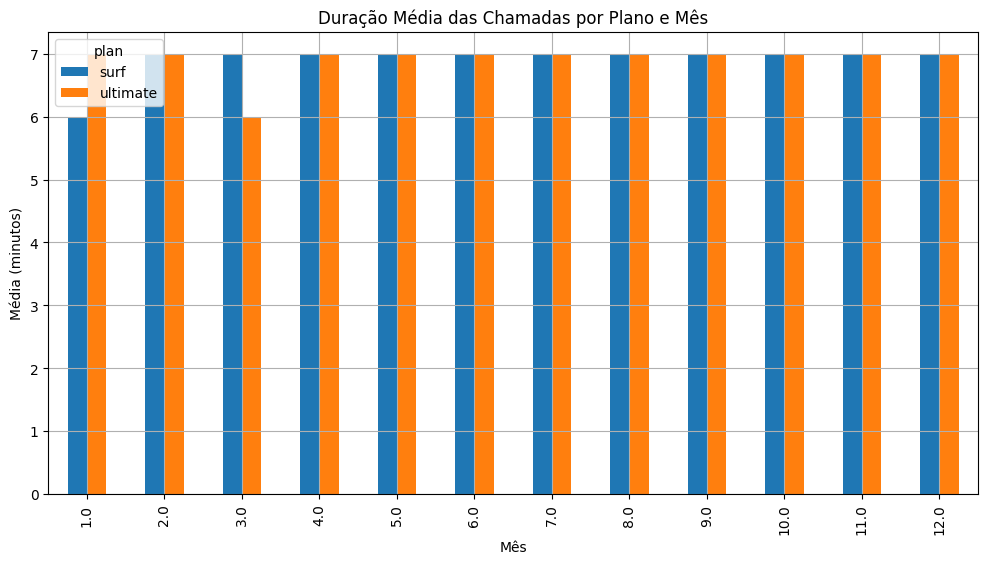

In [27]:
# Compare a duração média das chamadas de cada plano para cada mês. Crie um gráfico de barras para visualizar o resultado.
calls['duration'] = calls['duration'].round()
calls['month'] = calls['call_date'].dt.month 
calls_with_plan = calls.merge(users[['user_id', 'plan']], on='user_id', how='outer')

duration_by_plan_month = (calls_with_plan.groupby(['plan', 'month'])['duration'].mean().reset_index(name='avg_duration').round())
duration_pivot = duration_by_plan_month.pivot(index='month', columns='plan', values='avg_duration')

display(duration_by_plan_month)

duration_pivot.plot(kind='bar', 
                    title='Duração Média das Chamadas por Plano e Mês', 
                    xlabel='Mês', 
                    ylabel='Média (minutos)',
                    grid=True,
                    figsize=(12, 6))

plt.show()

<div class="alert alert-block alert-danger">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

- precisa discriminar por plano pois é importante comparar mensalmetne
</div>

<div class="alert alert-block alert-success">
<b> Comentário do revisor V2: </b> <a class="tocSkip"></a>

Correto
</div>


1       173.0
2       297.0
3       374.0
4       404.0
5       394.0
        ...  
2253    326.0
2254    328.0
2255    361.0
2256    287.0
2257    463.0
Name: duration, Length: 1545, dtype: float64
0       117.0
19       10.0
20       54.0
26      451.0
27      422.0
        ...  
2223    503.0
2224    424.0
2225    470.0
2226    450.0
2242    276.0
Name: duration, Length: 713, dtype: float64


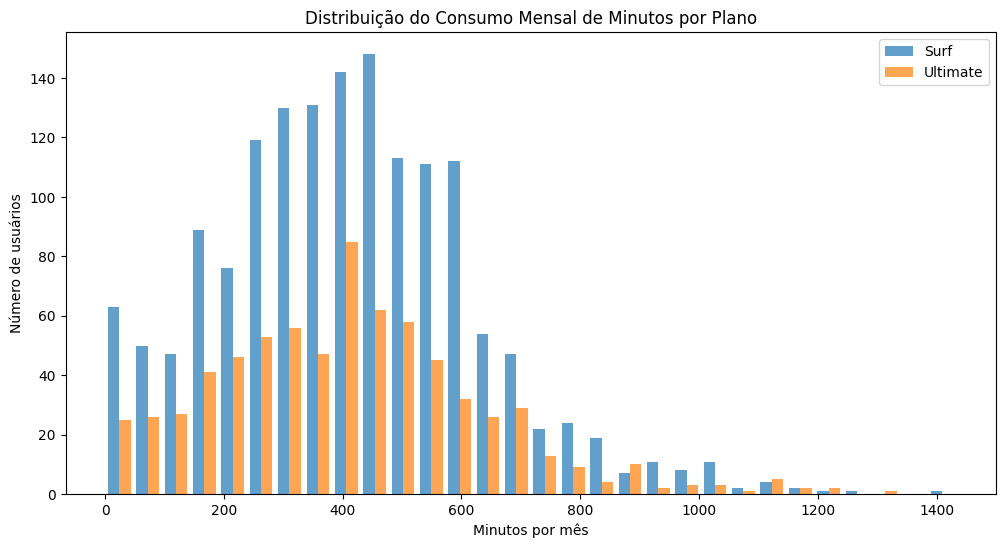

In [28]:
# Compare o número de minutos que os usuários de cada plano necessitam a cada mês. Construa um histograma.
minutes_per_users_monthly = calls_with_plan.groupby(['user_id','plan','month'])['duration'].sum().reset_index()

all_per_surf = minutes_per_users_monthly[minutes_per_users_monthly['plan'] == 'surf']['duration']
all_per_ultimate = minutes_per_users_monthly[minutes_per_users_monthly['plan'] == 'ultimate']['duration']

print(all_per_surf)
print(all_per_ultimate)

plt.figure(figsize=(12, 6))
plt.hist([all_per_surf, all_per_ultimate], bins=30, alpha=0.7, label=['Surf', 'Ultimate'])
plt.xlabel('Minutos por mês')
plt.ylabel('Número de usuários')
plt.title('Distribuição do Consumo Mensal de Minutos por Plano')

plt.legend()

plt.show()

[Calcule a média e a variância da duração das chamadas para refletir se os usuários de cada plano possuem comportamentos diferentes sobre as chamadas.]

In [29]:
# Calcule a média e a variância da duração mensal das chamadas
mean = minutes_per_users_monthly['duration'].mean()
variance = minutes_per_users_monthly['duration'].var()

print(mean)
print(variance)

411.3839681133747
48038.51488686119


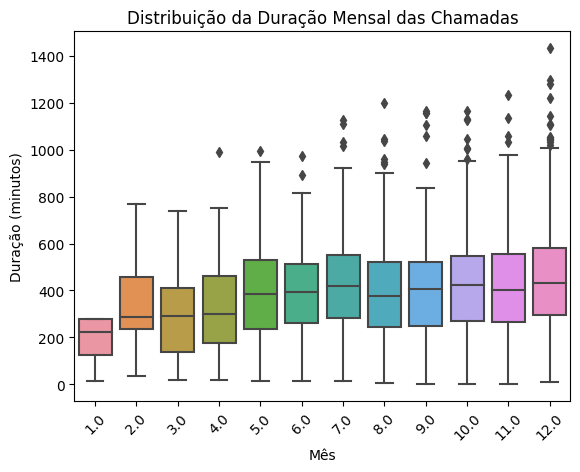

In [30]:
# Faça um diagrama de caixa para visualizar a distribuição da duração mensal das chamadas
sn.boxplot(data=minutes_per_users_monthly, x='month', y='duration')
plt.title('Distribuição da Duração Mensal das Chamadas')
plt.xlabel('Mês')
plt.ylabel('Duração (minutos)')
plt.xticks(rotation=45)
plt.show()

[Formule conclusões sobre como os usuários se comportam em termos de chamadas. O comportamento é diferente dependendo do plano?]

### Mensagens

In [31]:
# Compare o número de mensagens que os usuários de cada plano costumam enviar a cada mês
messages['month'] = messages['message_date'].dt.month
number_of_messages = messages.groupby(['user_id','month']).size().reset_index(name='Number of Messages')

number_of_monthly_messages_per_users = number_of_messages.merge(users[['user_id', 'plan']],
                                                                on='user_id', 
                                                                how='outer')
display(number_of_monthly_messages_per_users.nunique())
print()
comparison = number_of_monthly_messages_per_users.groupby(['plan', 'month'])['Number of Messages'].mean().unstack('plan').round()
display(comparison)

user_id               500
month                  12
Number of Messages    152
plan                    2
dtype: int64

plan,surf,ultimate
month,,
1.0,21.0,21.0
2.0,22.0,25.0
3.0,22.0,35.0
4.0,24.0,29.0
5.0,33.0,44.0
6.0,34.0,36.0
7.0,36.0,41.0
8.0,38.0,48.0
9.0,40.0,46.0


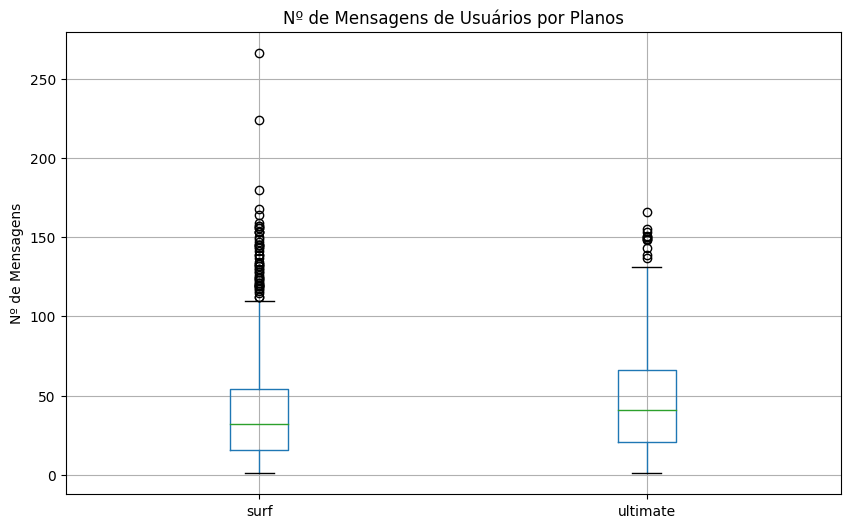

In [32]:
# Compare o número de mensagens que os usuários de cada plano costumam enviar a cada mês
boxplot_data = number_of_monthly_messages_per_users.pivot(columns='plan', values='Number of Messages')
boxplot_data.boxplot(figsize=(10, 6))
plt.title('Nº de Mensagens de Usuários por Planos')
plt.ylabel('Nº de Mensagens')
plt.show()

<div class="alert alert-block alert-danger">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

- precisa apresentar gráficos (baras, boxplot) discriminando por plano pois é importante comparar mensalmetne
</div>

<div class="alert alert-block alert-success">
<b> Comentário do revisor V2: </b> <a class="tocSkip"></a>

Houve  melhoras pois apresentou boxplot. Parabéns
</div>


### Internet

In [33]:
# Compare a quantidade de tráfego de internet consumido pelos usuários por plano
internet_with_plan = internet.merge(users[['user_id', 'plan']], on='user_id', how='left')
usage_per_user = internet_with_plan.groupby(['user_id', 'plan'])['gb_used'].sum().reset_index()
usage_per_user.columns = ['user_id', 'plan', 'total_gb_consumed']

print(usage_per_user.head(10))

   user_id      plan  total_gb_consumed
0     1000  ultimate                2.0
1     1001      surf               58.0
2     1002      surf               27.0
3     1003      surf               25.0
4     1004      surf              110.0
5     1005      surf               12.0
6     1006  ultimate               32.0
7     1007      surf              140.0
8     1008  ultimate               40.0
9     1009      surf              174.0


In [34]:
comparing_plan = usage_per_user.groupby(['user_id','plan'])['total_gb_consumed'].mean().unstack('plan').round()
display(comparing_plan.sample(50))

plan,surf,ultimate
user_id,,
1050,NaN,113.0
1033,NaN,62.0
1379,85.0,NaN
1168,4.0,NaN
1305,82.0,NaN
1252,73.0,NaN
1077,NaN,218.0
1438,48.0,NaN
1212,48.0,NaN


[Formule conclusões sobre como os usuários costumam consumir o tráfego da internet. O comportamento é diferente dependendo do plano?]

In [35]:
usage_per_plan = usage_per_user.groupby('plan')['total_gb_consumed'].agg(['mean', 'median', 'std']).round(2)
print("Consumo de internet por plano:")
display(usage_per_plan)

Consumo de internet por plano:


,mean,median,std
plan,,,
surf,62.80,47.0,52.49
ultimate,64.19,47.0,60.82


<Figure size 1000x600 with 0 Axes>

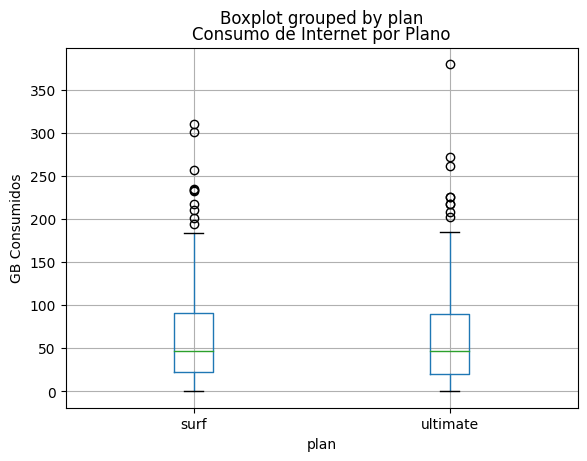

In [36]:
plt.figure(figsize=(10, 6))
usage_per_user.boxplot(column='total_gb_consumed', by='plan')
plt.title('Consumo de Internet por Plano')
plt.ylabel('GB Consumidos')
plt.show()

O plano ultimate tem uma dispersão maior em relação ao plano surf.
A mediana dos planos são iguais, isso significa que os usuários consomente geralmente a mesma quantidade de internet entre os 2 planos.
A média é maior para o plano de ultimate, com isso alguns usuários desse plano consomem mais internet.
Os dados de consumo em GB no plano de ultimate estão mais dispersados.

<div class="alert alert-block alert-danger">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

- precisa apresentar gráfico barras discriminando por plano pois é importante comparar mensalmetne
</div>

<div class="alert alert-block alert-success">
<b> Comentário do revisor V2: </b> <a class="tocSkip"></a>

Correto
</div>


## Receita

[Da mesma forma que você estudou o comportamento dos usuários, descreva estatisticamente as receitas dos planos.]

In [37]:
final_result['excess_messages'] = np.maximum(final_result['total_messages'] - final_result['messages_included'], 0)
final_result['revenue_messages'] = final_result['excess_messages'] * final_result['usd_per_message']

final_result['total_mb_used'] = final_result['Total_traffic'] * 1024  # converter GB para MB
final_result['excess_mb'] = np.maximum(final_result['total_mb_used'] - final_result['mb_per_month_included'], 0)
final_result['excess_gb'] = final_result['excess_mb'] / 1024
final_result['revenue_internet'] = final_result['excess_gb'] * final_result['usd_per_gb']

final_result['total_revenue'] = (final_result['usd_monthly_pay'] + 
                                final_result['revenue_minutes'] + 
                                final_result['revenue_messages'] + 
                                final_result['revenue_internet'])
display(final_result.sample(10))

,user_id,total_calls,month,duration,total_messages,Total_traffic,plan,messages_included,mb_per_month_included,minutes_included,...,gb_per_month_included,excess_minutes,revenue_minutes,excess_messages,revenue_messages,total_mb_used,excess_mb,excess_gb,revenue_internet,total_revenue
2705,1113,0.0,1,0.0,9.0,0.0,ultimate,1000,30720,3000,...,30.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,70.0
1756,1385,610.0,11,332.0,31.0,13.0,surf,50,15360,500,...,15.0,0.0,0.0,0.0,0.0,13312.0,0.0,0.0,0.0,20.0
369,1077,1224.0,10,498.0,71.0,23.0,ultimate,1000,30720,3000,...,30.0,0.0,0.0,0.0,0.0,23552.0,0.0,0.0,0.0,70.0
3083,1194,0.0,1,0.0,11.0,0.0,surf,50,15360,500,...,15.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0
3468,1283,0.0,8,0.0,2.0,0.0,ultimate,1000,30720,3000,...,30.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,70.0
1976,1433,288.0,11,556.0,89.0,23.0,ultimate,1000,30720,3000,...,30.0,0.0,0.0,0.0,0.0,23552.0,0.0,0.0,0.0,70.0
2902,1151,0.0,5,0.0,13.0,0.0,surf,50,15360,500,...,15.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0
429,1091,114.0,11,503.0,28.0,6.0,ultimate,1000,30720,3000,...,30.0,0.0,0.0,0.0,0.0,6144.0,0.0,0.0,0.0,70.0
2156,1475,228.0,12,238.0,59.0,12.0,ultimate,1000,30720,3000,...,30.0,0.0,0.0,0.0,0.0,12288.0,0.0,0.0,0.0,70.0
2345,1018,0.0,6,0.0,1.0,0.0,surf,50,15360,500,...,15.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0


In [38]:
revenue_by_plan = final_result.groupby('plan')['total_revenue'].agg(['mean', 'median', 'std']).round(2)
print("Receita por plano:")
display(revenue_by_plan)

Receita por plano:


,mean,median,std
plan,,,
surf,32.47,20.0,39.45
ultimate,71.02,70.0,7.72


<Figure size 1200x600 with 0 Axes>

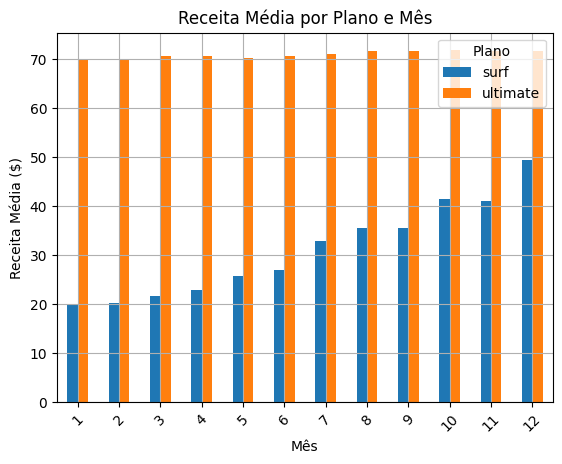

In [39]:
revenue_by_plan_month = final_result.groupby(['plan', 'month'])['total_revenue'].mean().reset_index()
revenue_pivot = revenue_by_plan_month.pivot(index='month', columns='plan', values='total_revenue')

plt.figure(figsize=(12, 6))
revenue_pivot.plot(kind='bar', 
                   title='Receita Média por Plano e Mês',
                   xlabel='Mês',
                   ylabel='Receita Média ($)',
                   grid=True)
plt.legend(title='Plano')
plt.xticks(rotation=45)
plt.show()

O Surf tem receita média menor, mas mediana maior, sugerindo que usuários que excedem os limites pagam 
valores altos. 
O Ultimate, apesar da taxa fixa alta, tem receita mais previsível (menor desvio padrão) 
e pode ser mais atrativo comercialmente pela estabilidade.

<div class="alert alert-block alert-danger">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

- precisa apresentar gráfico barras discriminando por plano pois é importante comparar mensalmetne
</div>

<div class="alert alert-block alert-success">
<b> Comentário do revisor V2: </b> <a class="tocSkip"></a>

Correto
</div>


## Teste hipóteses estatísticas

[Teste a hipótese de que a receita média dos usuários dos planos Ultimate e Surf são diferentes.]

[Formule as hipóteses nula e alternativa, escolha o teste estatístico, escolha o valor alfa.]

In [40]:
ultimate_revenue = final_result[final_result['plan'] == 'ultimate']['total_revenue'].dropna()
surf_revenue = final_result[final_result['plan'] == 'surf']['total_revenue'].dropna()
print(ultimate_revenue.var() == surf_revenue.var())
print('variancias diferentes')
alpha = 0.05

#results = st.ttest_ind(ultimate_revenue,surf_revenue)
results = st.ttest_ind(ultimate_revenue,surf_revenue, equal_var=False)
print('valor-p', results.pvalue)

if results.pvalue < alpha:
    print("Rejeitamos a hipótese nula pois não podemos afirmar que a receita média dos planos são iguais")
else:
    print("Não podemos rejeitar a hipótese nula pois a receita média dos planos pode ter a média semelhante")


False
variancias diferentes
valor-p 0.0
Rejeitamos a hipótese nula pois não podemos afirmar que a receita média dos planos são iguais


<div class="alert alert-block alert-danger">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

Precisamos seguir estes passos para o teste de hipótese:
- Definir a hipótese nula (ex: a altura média é igual entre homem e mulheres)
- Definir a hipótese alternativa (ex: a altura média não é igual entre homem e mulheres)
- Avaliar se as variâncias são iguais, por exemplo, calculando a variância da amostra e verificando a igualdade (ex: sample1.var() == sample2.var())
- Em seguida, ajustar equal_var=True no teste T se as variâncias forem iguais, senão usamos equal_var=False no teste T: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html.
- Avaliar o resultado do teste T

</div>

<div class="alert alert-block alert-success">
<b> Comentário do revisor V2: </b> <a class="tocSkip"></a>

Correto mas veja como ajustei o parâmetro equal_var. Além disso, faltou definir as hipóteses. H0: não há diferença etre as médias; H1: há diferença entre as médias
</div>


[Teste a hipótese de que a receita média dos usuários da área de NY-NJ difere dos usuários das demais regiões.]

[Formule as hipóteses nula e alternativa, escolha o teste estatístico, escolha o valor alfa.]

In [41]:
# Teste as hipóteses
ny_nj_users = users[users['city'].str.contains('NY-NJ', na=False)]['user_id']

ny_nj_revenue = final_result[final_result['user_id'].isin(ny_nj_users)]['total_revenue'].dropna()
other_regions_revenue = final_result[~final_result['user_id'].isin(ny_nj_users)]['total_revenue'].dropna()
print(ny_nj_revenue.var() == other_regions_revenue.var())
print('variancias diferentes')
print(f"Receitas NY-NJ: {len(ny_nj_revenue)}")
print(f"Receitas outras regiões: {len(other_regions_revenue)}")

alpha = 0.05

#results = st.ttest_ind(ny_nj_revenue, other_regions_revenue)
results = st.ttest_ind(ny_nj_revenue, other_regions_revenue, equal_var=False)
print('\nvalor-p:', results.pvalue)

if results.pvalue < alpha:
    print("Rejeitamos a hipótese nula pois podemos afirmar que a receita média são iguais entre NY-NJ e outras")
else:
    print("Não podemos rejeitar a hipótese nula pois a receita média das regioes podem ser semelhantes")


False
variancias diferentes
Receitas NY-NJ: 677
Receitas outras regiões: 3707

valor-p: 5.117182688503748e-05
Rejeitamos a hipótese nula pois podemos afirmar que a receita média são iguais entre NY-NJ e outras


<div class="alert alert-block alert-danger">
<b> Comentário do revisor: </b> <a class="tocSkip"></a>

Precisamos seguir estes passos para o teste de hipótese:
- Definir a hipótese nula (ex: a altura média é igual entre homem e mulheres)
- Definir a hipótese alternativa (ex: a altura média não é igual entre homem e mulheres)
- Avaliar se as variâncias são iguais, por exemplo, calculando a variância da amostra e verificando a igualdade (ex: sample1.var() == sample2.var())
- Em seguida, ajustar equal_var=True no teste T se as variâncias forem iguais, senão usamos equal_var=False no teste T: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html.
- Avaliar o resultado do teste T

</div>

<div class="alert alert-block alert-success">
<b> Comentário do revisor V2: </b> <a class="tocSkip"></a>

Correto mas veja como ajustei o parâmetro equal_var. Além disso, faltou definir as hipóteses. H0: não há diferença etre as médias; H1: há diferença entre as médias
</div>


## Conclusão geral

[Liste suas conclusões importantes nesta seção final, certifique-se de que elas cobrem todas as decisões (suposições) importantes que você tomou e que levaram à maneira como você processou e analisou os dados.]

Como conclusão final, vimos que o plano ultimate e surf por mais que tenham uma mediana igual, possuem duas diferenças também onde os dados de consumo de internet do ultimate são menos previsíveis e o de surf são mais pevisíveis, isso por causa da possibilidade e liberdade que os usuários tem no plano ultimate onde possuem maiores chances de gastar mais ou gastar menos de acordo com a sua necessidade.

O Surf tem receita média menor, mas mediana maior, sugerindo que usuários que excedem os limites pagam valores altos. O Ultimate, apesar da taxa fixa alta, tem receita mais previsível (menor desvio padrão) e pode ser mais atrativo comercialmente pela estabilidade.

sobre o teste de hipotese receita média de usuários por planos, a decisão estatística é que Rejeitamos a hipótese nula com confiança extremamente alta (praticamente 100%) e há evidência estatística muito forte de que as receitas médias dos planos Ultimate e Surf são diferentes
E na linguagem de negócios os usuários dos planos Ultimate e Surf definitivamente têm receitas médias diferentes